# 02 Optimal mix

Which mix of solar PV, battery and diesel generator supplies Umon South at the lowest cost, while keeping the clinic and school always on and letting households go without at most 5 % of their yearly energy?

The model (`src/model.py`, PyPSA with the free HiGHS solver) chooses the sizes and the hour-by-hour operation for one year at once. Three designs are compared: **diesel only**, **solar + battery** (no generator), and the **optimal hybrid** (the model may use all three). Each is run for both household demand cases and both clinic cases (12 runs). Costs are the approved table in `docs/cost_table.md`.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("ramp").setLevel(logging.ERROR)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG, PROC = ROOT / "figures", ROOT / "data" / "processed"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 2); pd.set_option("display.max_columns", 30)
import model as m, costs as cst, solar, demand as dm, data_sources as ds

In [2]:
# Inputs from notebook 01 (rebuilt if missing)
if not (PROC / "demand.parquet").exists():
    PROC.mkdir(parents=True, exist_ok=True); dm.build_all().to_parquet(PROC / "demand.parquet")
if not (PROC / "pv_per_kwp.parquet").exists():
    solar.pv_per_kwp().to_frame().to_parquet(PROC / "pv_per_kwp.parquet")
d = pd.read_parquet(PROC / "demand.parquet")
pv = pd.read_parquet(PROC / "pv_per_kwp.parquet")["pv_per_kwp"]
cst.table()[["item", "value", "unit", "naira", "source"]]

,item,value,unit,naira,source
0,pv_capex,441.00,$/kWp,6.14e+05,ESMAP 2022 Table 1.4 median (incl. PV inverter)
1,battery_capex,314.00,$/kWh,4.37e+05,"ESMAP 2022 Table 1.4 median, Li-ion"
2,inverter_capex,415.00,$/kW,5.78e+05,"ESMAP 2022 Table 1.4 median, inverter + EMS"
3,genset_capex,172.00,$/kW,2.39e+05,"Esan 2019: $48,286 for 350 kVA, at pf 0.8; equ..."
4,bos_per_kwp,340.00,$/kWp,4.73e+05,"ESMAP 2022 Fig. 1.10, 2021 average BOS, read f..."
5,pv_om,10.00,$/kW/yr,1.39e+04,ESMAP 2022 note 12
6,battery_om,10.00,$/kW/yr,1.39e+04,ESMAP 2022 note 12 (per kW of inverter)
7,genset_om,0.03,$/kWh,4.18e+01,"ESMAP 2022 note 12, non-fuel"
8,distribution_per_customer,250.00,$/customer,3.48e+05,"ESMAP 2022 Table 1.4 median, distribution and ..."
9,staff_per_year,5100.00,$/yr,7.10e+06,"ESMAP 2022 modelling assumptions, 3 staff up t..."


In [3]:
ann = cst.annual_costs()
pd.Series({"PV incl. balance of system, per kWp per year": ann["pv_per_kwp_yr"], "battery, per kWh of storage per year": ann["battery_per_kwh_yr"],
           "inverter, per kW per year": ann["inverter_per_kw_yr"], "generator, per kW per year": ann["genset_per_kw_yr"],
           "generator electricity, per kWh (fuel + upkeep + wear)": ann["genset_per_kwh"],
           "diesel delivered, per litre": ann["fuel_usd_per_l"]}, name="US$").to_frame()

,US$
"PV incl. balance of system, per kWp per year",98.52
"battery, per kWh of storage per year",51.10
"inverter, per kW per year",77.54
"generator, per kW per year",20.20
"generator electricity, per kWh (fuel + upkeep + wear)",0.96
"diesel delivered, per litre",2.68


## 1. Twelve runs

In [4]:
res, nets = m.run_cases(d, pv, m.main_cases())
res.to_parquet(PROC / "results_main.parquet")
cols = ["PV kWp", "battery kWh", "inverter kW", "diesel kW", "diesel share %", "hours with household shortfall",
        "longest shortfall h", "battery full cycles/yr", "battery life years", "LCOE generation $/kWh",
        "LCOE delivered $/kWh", "LCOE delivered N/kWh", "CO2 t/yr"]
res[cols]

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


,PV kWp,battery kWh,inverter kW,diesel kW,diesel share %,hours with household shortfall,longest shortfall h,battery full cycles/yr,battery life years,LCOE generation $/kWh,LCOE delivered $/kWh,LCOE delivered N/kWh,CO2 t/yr
case,,,,,,,,,,,,,
diesel_only | demand low | clinic low,0.00,0.00,0.00,11.60,100.00,1434,4,0.00,10.00,0.97,1.27,1762.06,43.00
pv_battery | demand low | clinic low,51.22,135.15,16.83,0.00,0.00,428,7,320.81,9.35,0.29,0.59,814.65,0.00
hybrid | demand low | clinic low,51.22,135.15,16.83,0.00,0.00,398,7,320.69,9.35,0.29,0.59,814.60,0.00
diesel_only | demand low | clinic high,0.00,0.00,0.00,12.12,100.00,1365,4,0.00,10.00,0.97,1.23,1712.62,48.70
pv_battery | demand low | clinic high,59.39,143.42,17.87,0.00,0.00,431,6,318.77,9.41,0.28,0.54,752.80,0.00
hybrid | demand low | clinic high,58.82,143.07,17.99,0.03,0.12,397,7,318.91,9.41,0.28,0.54,752.79,0.06
diesel_only | demand high | clinic low,0.00,0.00,0.00,46.51,100.00,1531,5,0.00,10.00,0.97,1.04,1447.90,173.26
pv_battery | demand high | clinic low,200.54,563.81,69.61,0.00,0.00,463,6,322.03,9.32,0.29,0.36,505.32,0.00
hybrid | demand high | clinic low,200.54,563.81,69.61,0.00,0.00,432,8,321.98,9.32,0.29,0.36,505.30,0.00


Every run passed the hand checks: supply equals demand in every hour, the battery stays between 20 % and 100 % of its size, and the yearly cost recomputed from sizes and flows outside PyPSA matches the solver's objective.

In [5]:
pd.DataFrame({name: m.check(n, res.loc[name]) for name, n in nets.items()}).T.drop(columns=["battery min / max state (share of size)"], errors="ignore")

,max hourly imbalance kW,cost recomputed vs objective (rel. diff),ok
diesel_only | demand low | clinic low,0.0,0.0,True
pv_battery | demand low | clinic low,0.0,0.0,True
hybrid | demand low | clinic low,0.0,0.0,True
diesel_only | demand low | clinic high,0.0,0.0,True
pv_battery | demand low | clinic high,0.0,0.0,True
hybrid | demand low | clinic high,0.0,0.0,True
diesel_only | demand high | clinic low,0.0,0.0,True
pv_battery | demand high | clinic low,0.0,0.0,True
hybrid | demand high | clinic low,0.0,0.0,True
diesel_only | demand high | clinic high,0.0,0.0,True


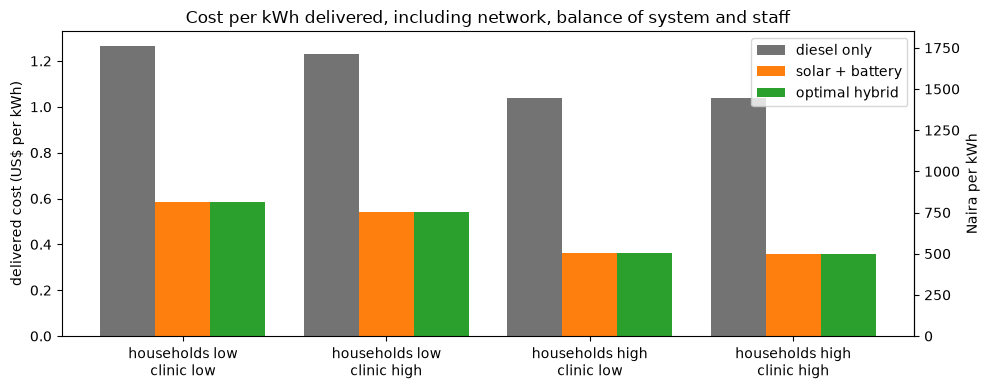

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
labels = {"diesel_only": "diesel only", "pv_battery": "solar + battery", "hybrid": "optimal hybrid"}
groups = [(dm_, cl) for dm_ in ("low", "high") for cl in ("low", "high")]
x = np.arange(len(groups)); w = 0.27
for i, (design, colour) in enumerate([("diesel_only", "0.45"), ("pv_battery", "tab:orange"), ("hybrid", "tab:green")]):
    vals = [res.loc[f"{design} | demand {a} | clinic {b}", "LCOE delivered $/kWh"] for a, b in groups]
    ax.bar(x + (i - 1) * w, vals, w, color=colour, label=labels[design])
ax.set_xticks(x, [f"households {a}\nclinic {b}" for a, b in groups])
ax.set_ylabel("delivered cost (US$ per kWh)"); ax.legend()
ax.set_title("Cost per kWh delivered, including network, balance of system and staff")
sec = ax.secondary_yaxis("right", functions=(lambda v: v * cst.FX_NGN_PER_USD, lambda v: v / cst.FX_NGN_PER_USD))
sec.set_ylabel("Naira per kWh")
fig.tight_layout(); fig.savefig(FIG / "lcoe_by_design.png", dpi=150)

## 2. How the optimised system runs

The optimal hybrid for the high household case: one dry-season week (January) and the rainy-season week with the most unserved household energy. **The optimisation knows the whole year's weather in advance**, so in the rainy week it rations households on several evenings while the battery still holds charge, to get through the cloudy spell. Section 4 shows what happens without that foresight.

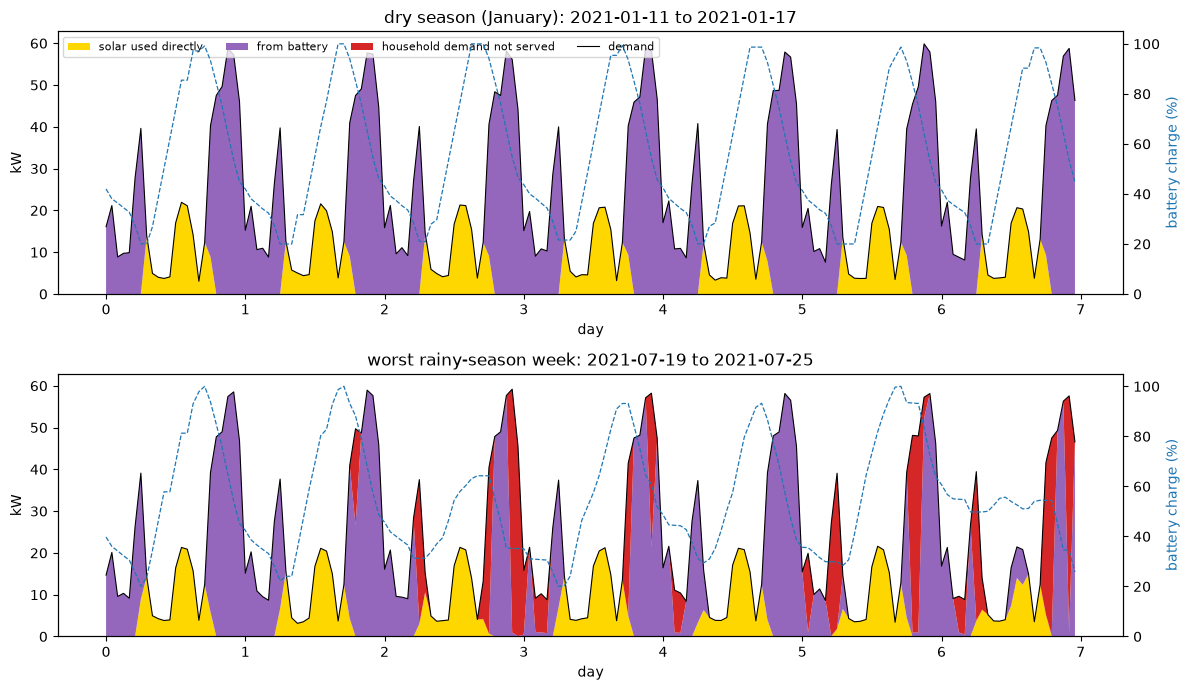

In [7]:
name = "hybrid | demand high | clinic low"
n = nets[name]
g, L = n.generators_t.p, n.loads_t.p
discharge = n.links_t.p1["inverter discharge"].abs(); charge = n.links_t.p0["inverter charge"]
soc = n.stores_t.e["battery"] / n.stores.at["battery", "e_nom_opt"]
weekly_short = g["unserved"].resample("W").sum()
weeks = {"dry season (January)": ("2021-01-11", "2021-01-17"),
         "worst rainy-season week": ((weekly_short.idxmax() - pd.Timedelta(days=6)).strftime("%Y-%m-%d"), weekly_short.idxmax().strftime("%Y-%m-%d"))}
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharey=True)
for ax, (title, (a, b)) in zip(axs, weeks.items()):
    sl = slice(a, f"{b} 23:00")
    pv_used = (g["pv"] - charge).clip(lower=0)[sl]
    t = np.arange(len(pv_used)) / 24
    ax.stackplot(t, pv_used, discharge[sl], g["unserved"][sl], colors=["gold", "tab:purple", "tab:red"],
                 labels=["solar used directly", "from battery", "household demand not served"])
    ax.plot(t, L.sum(axis=1)[sl], "k", lw=0.8, label="demand")
    ax2 = ax.twinx(); ax2.plot(t, soc[sl] * 100, color="tab:blue", lw=0.9, ls="--"); ax2.set_ylim(0, 105)
    ax2.set_ylabel("battery charge (%)", color="tab:blue")
    ax.set_title(f"{title}: {a} to {b}"); ax.set_ylabel("kW"); ax.set_xlabel("day")
axs[0].legend(loc="upper left", fontsize=8, ncol=4)
fig.tight_layout(); fig.savefig(FIG / "dispatch_weeks.png", dpi=150)

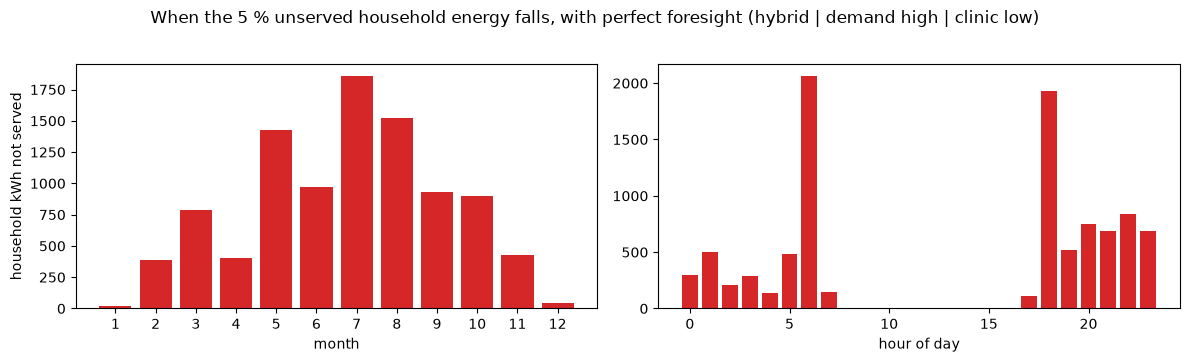

In [8]:
u = n.generators_t.p["unserved"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].bar(range(1, 13), u.groupby(u.index.month).sum().reindex(range(1, 13), fill_value=0), color="tab:red")
axs[0].set_xlabel("month"); axs[0].set_ylabel("household kWh not served"); axs[0].set_xticks(range(1, 13))
axs[1].bar(range(24), u.groupby(u.index.hour).sum().reindex(range(24), fill_value=0), color="tab:red")
axs[1].set_xlabel("hour of day"); axs[1].set_title("")
fig.suptitle(f"When the 5 % unserved household energy falls, with perfect foresight ({name})", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "shortfall_timing.png", dpi=150, bbox_inches="tight")

## 4. Without perfect foresight

A real operator does not know next week's weather. `model.simulate_rule` runs the optimised sizes with a simple rule and no foresight: solar first, then within each hour the battery serves the clinic and school first (down to its 20 % floor) and households next, then the generator if there is one; whatever is still missing is cut from households, and from the clinic and school only if nothing else is left. Without any remedy this rule still cuts the clinic and school in some hours, because the battery is empty by then. Two remedies are compared, for all four demand cases:

- **a battery reserve:** households are served from the battery only while its charge is above a threshold (share of its size), so the last of the charge is kept for the clinic and school. The table gives the *smallest* threshold (0.20 to 0.45 in steps of 0.01) that leaves no clinic/school hour cut.
- **a small backup generator** sized to the clinic and school peak, used only when the battery cannot serve them.

In [9]:
rows = []
for c in m.main_cases():
    if c.design != "hybrid": continue
    n_, s_ = nets[c.name], res.loc[c.name].to_dict() | {"case": c.name}
    rv = m.reserve_vs_backup(n_, s_, c, d, pv)
    base = {"households unserved %": s_["unserved % of households"], "clinic/school hours cut": 0}
    rows += [
        {"case": f"{c.demand} / {c.clinic}", "operation": "optimisation (perfect foresight)", **base,
         "household hours": s_["hours with household shortfall"], "longest outage h": s_["longest shortfall h"], "diesel litres/yr": 0.0},
        {"case": "", "operation": "rule, no remedy", "households unserved %": rv["plain rule: household %"],
         "clinic/school hours cut": rv["plain rule: critical hours cut"], "household hours": rv["plain rule: household hours"],
         "longest outage h": rv["plain rule: longest outage h"], "diesel litres/yr": 0.0},
        {"case": "", "operation": f"rule + minimum reserve ({rv['threshold']:.0%} charge)", "households unserved %": rv["reserve: household %"],
         "clinic/school hours cut": 0, "household hours": rv["reserve: household hours"],
         "longest outage h": rv["reserve: longest outage h"], "diesel litres/yr": rv["reserve: litres/yr"]},
        {"case": "", "operation": f"rule + {rv['backup: kW']:.0f} kW backup generator", "households unserved %": rv["backup: household %"],
         "clinic/school hours cut": rv["backup: critical hours cut"], "household hours": rv["backup: household hours"],
         "longest outage h": rv["backup: longest outage h"], "diesel litres/yr": rv["backup: litres/yr"]}]
    print(f"{c.demand}/{c.clinic}: reserve loses {rv['reserve: extra household kWh lost']:.0f} kWh more of household energy than the plain rule; "
          f"backup costs ${rv['backup: annual cost $/yr']:.0f}/yr and {rv['backup: litres/yr']:.0f} L; "
          f"delivered cost reserve ${rv['reserve: LCOE $/kWh']:.3f} vs backup ${rv['backup: LCOE $/kWh']:.3f} per kWh")
pd.DataFrame(rows).set_index(["case", "operation"]).round(1)

low/low: reserve loses 1735 kWh more of household energy than the plain rule; backup costs $212/yr and 53 L; delivered cost reserve $0.601 vs backup $0.588 per kWh
low/high: reserve loses 2878 kWh more of household energy than the plain rule; backup costs $354/yr and 89 L; delivered cost reserve $0.563 vs backup $0.544 per kWh
high/low: reserve loses 1818 kWh more of household energy than the plain rule; backup costs $216/yr and 55 L; delivered cost reserve $0.365 vs backup $0.364 per kWh
high/high: reserve loses 3199 kWh more of household energy than the plain rule; backup costs $355/yr and 89 L; delivered cost reserve $0.361 vs backup $0.359 per kWh


households unserved %  \
case        operation                                                    
low / low   optimisation (perfect foresight)                       5.0   
            rule, no remedy                                        4.6   
            rule + minimum reserve (26% charge)                    8.8   
            rule + 3 kW backup generator                           4.6   
low / high  optimisation (perfect foresight)                       5.0   
            rule, no remedy                                        4.5   
            rule + minimum reserve (29% charge)                   11.4   
            rule + 5 kW backup generator                           4.5   
high / low  optimisation (perfect foresight)                       5.0   
            rule, no remedy                                        4.9   
            rule + minimum reserve (22% charge)                    5.9   
            rule + 3 kW backup generator                           4.9   
high / high optimisation (perfect foresight)                       5.0   
            rule, no remedy                                        4.9   
            rule + minimum reserve (23% charge)                    6.5   
            rule + 5 kW backup generator                           4.9   

                                                 clinic/school hours cut  \
case        operation                                                      
low / low   optimisation (perfect foresight)                           0   
            rule, no remedy                                          282   
            rule + minimum reserve (26% charge)                        0   
            rule + 3 kW backup generator                               0   
low / high  optimisation (perfect foresight)                           0   
            rule, no remedy                                          280   
            rule + minimum reserve (29% charge)                        0   
            rule + 5 kW backup generator                               0   
high / low  optimisation (perfect foresight)                           0   
            rule, no remedy                                          288   
            rule + minimum reserve (22% charge)                        0   
            rule + 3 kW backup generator                               0   
high / high optimisation (perfect foresight)                           0   
            rule, no remedy                                          286   
            rule + minimum reserve (23% charge)                        0   
            rule + 5 kW backup generator                               0   

                                                 household hours  \
case        operation                                              
low / low   optimisation (perfect foresight)                 398   
            rule, no remedy                                  474   
            rule + minimum reserve (26% charge)              842   
            rule + 3 kW backup generator                     474   
low / high  optimisation (perfect foresight)                 397   
            rule, no remedy                                  443   
            rule + minimum reserve (29% charge)             1006   
            rule + 5 kW backup generator                     443   
high / low  optimisation (perfect foresight)                 432   
            rule, no remedy                                  524   
            rule + minimum reserve (22% charge)              749   
            rule + 3 kW backup generator                     524   
high / high optimisation (perfect foresight)                 416   
            rule, no remedy                                  503   
            rule + minimum reserve (23% charge)              785   
            rule + 5 kW backup generator                     503   

                                                 longest outage h  \
case        operation                                

Without foresight, the rule cuts the clinic and school in 280-290 hours a year in every case, even though the optimisation never did. The three ways of dealing with that trade off differently:

- **A minimum battery reserve** needs no equipment and no diesel. The smallest threshold that removes every clinic/school cut is 22-23 % of the battery (high household demand) and 26-29 % (low demand). It costs households energy: they lose 5.9-6.5 % (high) and 8.8-11.4 % (low) of theirs, against 4.5-4.9 % without it, i.e. 1,800-3,200 kWh a year more, on 750-1,000 hours instead of 440-520.
- **A backup generator** (3-5 kW, clinic and school only) leaves household service as it is (4.5-4.9 %), uses 53-89 litres of diesel and costs $210-355 a year.
- **Delivered cost per kWh is almost the same** either way (high demand: $0.365 with the reserve, $0.364 with the backup; low demand: $0.56-0.60 against $0.54-0.59), because the reserve sells less energy. So neither is cheaper: the choice is between households' energy (backup) and equipment, fuel logistics and a second machine to maintain (reserve costs none of those).

The **final design adds the backup generator** (author's choice, 26 Nov 2026); all results below come from the no-foresight rule.

In [10]:
final = pd.DataFrame([m.final_design(nets[c.name], res.loc[c.name].to_dict() | {"case": c.name}, c, d, pv)
                      for c in m.main_cases() if c.design == "hybrid"]).set_index("case")
final.to_parquet(PROC / "results_final.parquet")
final

,PV kWp,battery kWh,inverter kW,main diesel kW,backup generator kW,households unserved %,hours with household shortfall,longest household outage h,clinic/school hours cut,battery full cycles/yr,battery life years,diesel litres/yr,CO2 t/yr,backup capital $/yr,diesel running $/yr,battery wear extra $/yr,total cost $/yr,served kWh/yr,LCOE delivered $/kWh,LCOE delivered N/kWh
case,,,,,,,,,,,,,,,,,,,,
hybrid | demand low | clinic low,51.22,135.15,16.83,0.00,3.0,4.62,474,13,0,320.54,9.36,53.25,0.14,60.61,150.93,284.16,28015.05,47665.30,0.59,817.99
hybrid | demand low | clinic high,58.82,143.07,17.99,0.03,5.0,4.53,443,13,0,318.71,9.41,89.12,0.24,101.02,252.61,273.82,29390.69,54002.32,0.54,757.46
hybrid | demand high | clinic low,200.54,563.81,69.61,0.00,3.0,4.91,524,13,0,321.85,9.32,54.83,0.15,60.61,155.43,1261.54,69705.98,191583.80,0.36,506.38
hybrid | demand high | clinic high,208.16,571.42,70.76,0.00,5.0,4.86,503,13,0,321.63,9.33,89.46,0.24,101.02,253.59,1265.39,71076.85,197980.03,0.36,499.65


In [11]:
# When the final design (rule run, with backup) leaves households short: January and the rainy season
mon = {}
for c in m.main_cases():
    if c.design != "hybrid": continue
    crit = d.school + d[f"clinic_{c.clinic}"]
    r = m.simulate_rule(nets[c.name], c, d, pv, backup_kw=float(np.ceil(crit.max())))
    mon[f"{c.demand} / {c.clinic}"] = r["household kWh not served by month (rule)"]
mon = pd.DataFrame(mon, index=range(1, 13)); mon.index.name = "month"
out = mon.loc[[1]].round(1).rename(index={1: "January kWh unserved"})
out.loc["share in May-Oct %"] = 100 * mon.loc[5:10].sum() / mon.sum()
out.loc["total kWh unserved"] = mon.sum()
out.round(1)

,low / low,low / high,high / low,high / high
month,,,,
January kWh unserved,2.6,0.0,21.1,17.3
share in May-Oct %,78.3,78.7,78.6,78.8
total kWh unserved,1934.5,1895.4,9501.8,9403.4


## 3. Against RLI's own design for Umon South

The RLI/GIZ electrification plan also sized a mini-grid for this cluster. Its assumptions (costs, diesel price, year, demand) are not in the dataset, and the units of its sizes are not stated, so this is a rough comparison.

In [12]:
import shapefile
r = shapefile.Reader(str(ds.rli_cross_river() / "cluster_phases_State_Cross River.shp"))
rli = pd.DataFrame(r.records(), columns=[f[0] for f in r.fields[1:]]).set_index("ID").loc[ds.SITE["rli_id"]]
comp = pd.DataFrame({
    "RLI design (units assumed)": {"PV kWp": rli["_PV size"], "battery kWh": rli["_Battery s"], "diesel kW": rli["_Generator"],
                                   "renewable share %": rli["_RE Share"]},
    **{f"this study, {k} demand": {"PV kWp": res.loc[f"hybrid | demand {k} | clinic low", "PV kWp"],
                                   "battery kWh": res.loc[f"hybrid | demand {k} | clinic low", "battery kWh"],
                                   "diesel kW": res.loc[f"hybrid | demand {k} | clinic low", "diesel kW"],
                                   "renewable share %": 100 - res.loc[f"hybrid | demand {k} | clinic low", "diesel share %"]}
       for k in ("low", "high")}})
comp.round(1)

,RLI design (units assumed),"this study, low demand","this study, high demand"
PV kWp,96.0,51.2,200.5
battery kWh,168.0,135.2,563.8
diesel kW,77.0,0.0,0.0
renewable share %,65.6,100.0,100.0


## What this shows

- **At today's diesel price the least-cost design is solar plus battery.** With diesel delivered at about $2.68 a litre, a kWh from a generator costs about $0.96 in running costs alone, and diesel only delivers for $1.04-1.27 per kWh. In every case the optimiser builds no main generator (one case builds 0.04 kW).
- **But that design leans on perfect foresight.** The optimisation keeps the clinic and school on by rationing households ahead of cloudy spells it knows are coming. Operated with a simple rule and no foresight or reserve, the same system would cut the clinic and school for 280-290 hours a year.
- **Two fixes are compared (section 4).** A battery reserve of 22-29 % keeps the clinic on at the price of 1,800-3,200 kWh a year more lost by households; a 3-5 kW backup generator keeps them on in every hour, burns 53-89 litres of diesel a year and adds $210-355 a year, with households still short 4.5-4.9 % of their energy (440-520 hours a year, longest outage 13 hours, about 79 % of the unserved energy in May-October, 0-21 kWh in January).
- **Final design, high household demand:** 201-208 kWp of PV, 564-571 kWh of battery, a 70-71 kW inverter and a 3-5 kW backup generator, delivering at about **$0.36 per kWh (₦500-506)**. Low household demand: 51-59 kWp, 135-143 kWh, 17-18 kW, delivering at **$0.54-0.59 per kWh (₦757-818)**, dearer per kWh because the network and staff are spread over fewer kWh. Diesel only would cost $1.04 (high) and $1.23-1.27 (low).
- **The battery works hard.** It cycles about 320 times a year, a little above the 300 a year that 3,000 cycles over 10 years allows, so it wears out after about 9.3 years; that cost is included.
- **RLI's own design for this cluster** includes a 77 kW generator and a smaller battery, made under different, unstated assumptions (its demand and costs are not in the dataset). Notebook 03's diesel-price sweep shows at what price a main generator comes back here.

**Limits.** One typical weather year (no run of unusually cloudy years). A linear generator model (no minimum load or start-up cost), the half-load fuel rate and 2021 battery prices all favour diesel, so the case for solar plus battery is conservative. PV is annualised over 25 years inside a 20-year project, which credits its residual life. Balance of system is ESMAP's chart average per kWp and includes a genset that this model prices separately (small overlap). Battery wear counted after the fact. Median ESMAP costs, not quotes for this site. The no-foresight rule is deliberately simple; a smarter controller would do somewhat better than it.